# QASM interop

`from_unitary_qasm` and `to_unitary_qasm`, in `qaravan.interop`.

QASM angles are assumed to follow Qiskit's convention, $\exp(-i\theta P/2)$. Qaravan's
rotations are full-angle, $\exp(-i\theta P)$, so import halves and export doubles.

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

from qaravan.core.circuit import Circuit
from qaravan.core.fermions import FermionicEncoding
from qaravan.core.gates import (
    CNOT, CZ, RX, RXX, RY, RYY, RZ, RZZ, SWAP, SX, XY, H, I, MatrixGate, S, Sdg, T, Tdg, X, Y, Z, iSWAP,
)
from qaravan.core.hamiltonians import AndersonImpurity
from qaravan.interop import from_unitary_qasm, to_unitary_qasm
from qaravan.plot import set_style

set_style()
np.set_printoptions(precision=4, suppress=True)

## 1. QASM text in

In [4]:
text = """OPENQASM 2.0;
include "qelib1.inc";
// global_phase = 0.25
gate rzz(theta) a, b { cx a, b; rz(theta) b; cx a, b; }
qreg q[2];
h q[0];
rzz(0.8) q[0], q[1];
barrier q[0],q[1];
rx(pi/2) q[1];
"""

circuit = from_unitary_qasm(text, num_sites=2)
print(circuit.gates)
print("rx(pi/2) became RX(pi/4):", np.isclose(circuit.gates[-1].params[0], np.pi / 4))

[GlobalPhase([0]), H([0]), RZZ([0, 1], 0.4), RX([1], 0.7854)]
rx(pi/2) became RX(pi/4): True


## 2. Circuit out

In [5]:
print(to_unitary_qasm(Circuit([H(0), RZZ([0, 1], 0.4), SX(1)], num_sites=2)))

OPENQASM 2.0;
include "qelib1.inc";
gate rzz(theta) a, b { }
gate sx a { }
qreg q[2];
h q[0];
rzz(0.8) q[0], q[1];
sx q[1];



## 3. Round trip

Every supported gate, out and back. Angles survive bit-exactly, not just to `allclose` —
`repr(float(...))` is the shortest string that reads back as the same float64.

In [6]:
gates = [
    I(0), H(1), X(2), Y(0), Z(1), S(2), Sdg(0), T(1), Tdg(2), SX(0),
    CNOT([0, 1]), CZ([1, 2]), SWAP([0, 2]), iSWAP([1, 2]),
    RX(0, 0.3123), RY(1, -0.7311), RZ(2, 1.1907),
    RXX([0, 1], 0.4471), RYY([1, 2], -0.2213), RZZ([0, 2], 0.9137), XY([1, 2], 0.6029),
]
circuit = Circuit(gates, num_sites=3)
back = from_unitary_qasm(to_unitary_qasm(circuit), num_sites=3)

originals = [g.params[0] for g in circuit.gates if hasattr(g, "params")]
recovered = [g.params[0] for g in back.gates if hasattr(g, "params")]
print("unitary preserved:", np.allclose(circuit.to_matrix(), back.to_matrix()))
print("angles bit-exact:", originals == recovered)

# The doubling is only visible in the text; a round trip cancels it.
print(to_unitary_qasm(Circuit([RX(0, 0.3)], num_sites=1)).splitlines()[-1])

unitary preserved: True
angles bit-exact: True
rx(0.6) q[0];


## 4. What raises

In [7]:
for label, thunk in [
    ("qutrit circuit", lambda: to_unitary_qasm(Circuit([H(0)], num_sites=1, local_dim=3))),
    ("gate with no QASM name", lambda: to_unitary_qasm(Circuit([MatrixGate("Custom", [0], np.eye(2))], num_sites=1))),
    ("QASM name we don't know", lambda: from_unitary_qasm('OPENQASM 2.0;\nqreg q[2];\nch q[0], q[1];\n', num_sites=2)),
]:
    try:
        thunk()
    except NotImplementedError as exc:
        print(f"{label}: {exc}")

qutrit circuit: QASM is qubit-only; circuit has local_dim=3.
gate with no QASM name: Gate 'Custom' has no QASM equivalent -- not part of the gate vocabulary this exporter supports.
QASM name we don't know: QASM gate 'ch' has no Qaravan equivalent yet -- not part of the gate vocabulary this importer supports; add it if a Hamiltonian/gateset choice needs it.


## 5. Real Trotter circuits

`qasm/trotter_{order}_{n_steps}.qasm` are exporter output, not ours — one Trotter step each,
for a 3-bath Anderson impurity chain on 8 qubits. The Hamiltonian below is rebuilt
independently in Qaravan, so nothing in this check comes from the same source as the circuits.

Repeat each step `n_steps` times and compare against $e^{-iHT}$ at $T=1$. Total-time Trotter
error is $O(dt^{\rm order})$.

The order-1 fit uses only $dt \le 0.125$: $\|U-V\|_2/2 \le 1$ for unitaries, and the two
coarsest points are already at 0.99 and 0.94, so they are saturated, not asymptotic.

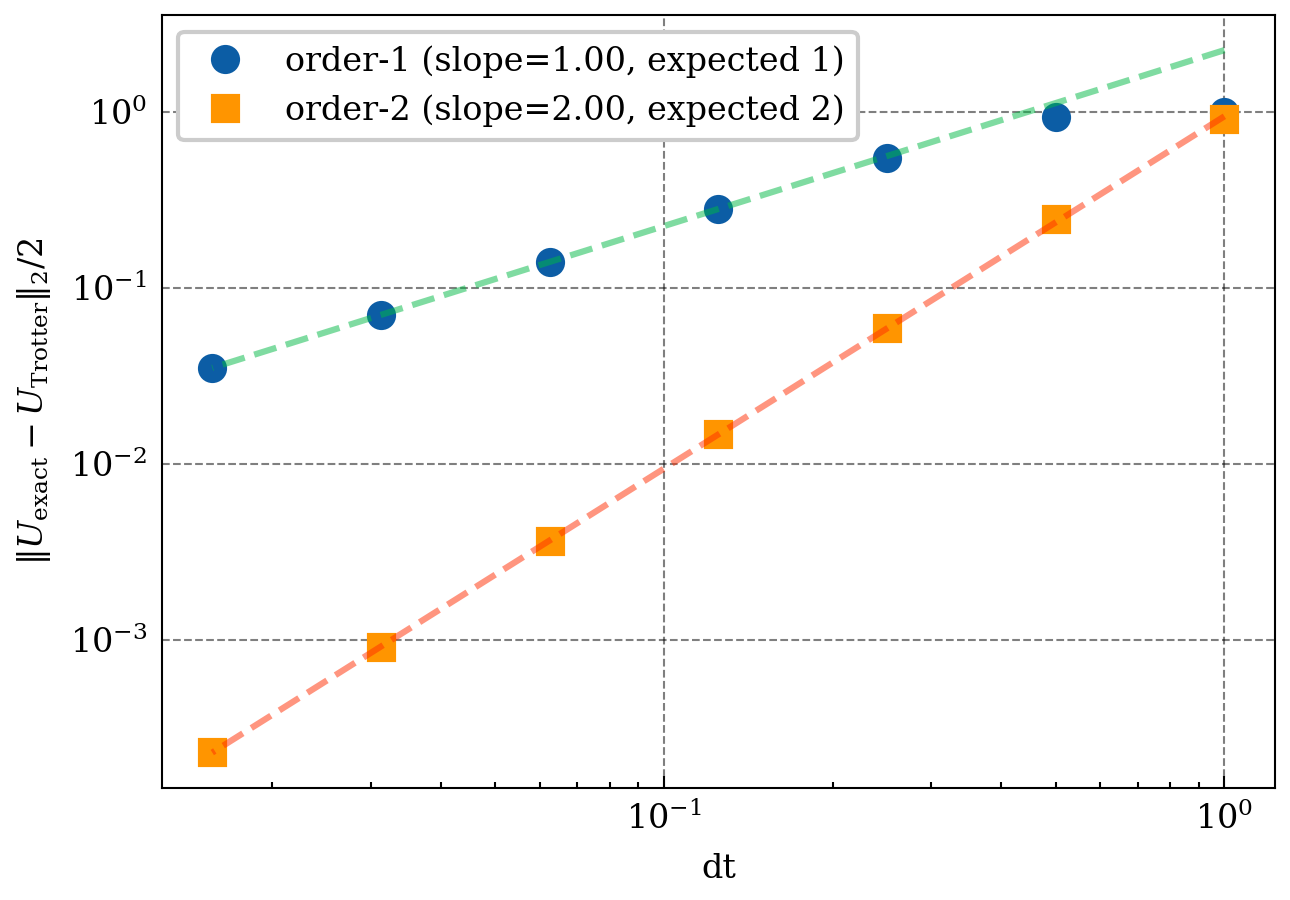

In [8]:
aim = AndersonImpurity.chain(
    eps_d=-1.309, U=3.232, eps_chain=[0.735, 1.587, 0.255], t_chain=[2.432, 1.513], V=0.988
)
ham = aim.encode(FermionicEncoding("jordan_wigner", num_modes=aim.num_fermionic_modes))
num_qubits = aim.num_fermionic_modes
total_time = 1.0
exact_propagator = expm(-1j * ham.to_matrix() * total_time)

step_counts = [1, 2, 4, 8, 16, 32, 64]

fig, ax = plt.subplots(figsize=(4.5, 3.2))
for order, marker in [(1, "o"), (2, "s")]:
    step_sizes, distances = [], []
    for n_steps in step_counts:
        text = open(f"qasm/trotter_{order}_{n_steps}.qasm").read()
        step = from_unitary_qasm(text, num_sites=num_qubits)
        trotter = (step * n_steps).to_matrix()
        step_sizes.append(total_time / n_steps)
        distances.append(np.linalg.norm(exact_propagator - trotter, ord=2) / 2)

    step_sizes, distances = np.array(step_sizes), np.array(distances)
    tail = step_sizes <= 0.125
    slope, intercept = np.polyfit(np.log(step_sizes[tail]), np.log(distances[tail]), 1)
    ax.loglog(step_sizes, distances, marker, label=f"order-{order} (slope={slope:.2f}, expected {order})")
    ax.loglog(step_sizes, np.exp(intercept) * step_sizes**slope, "--", alpha=0.5)

ax.set_xlabel("dt")
ax.set_ylabel(r"$\|U_{\rm exact} - U_{\rm Trotter}\|_2 / 2$")
ax.legend()
plt.tight_layout()